# Análise de Estabilidade Linear da Convecção Térmica e MRI em Discos de Acreção
- PET - Física
- Petiana: Ylana Karolina Santos Lopes
- Data: 02 de Outubro de 2026

$\quad$ O objetivo deste `Notebook` é fazer uma análise linear da estabilidade baseada no artigo de Mamatsashvili et al. 2013  em um disco de acreção. Com isso, expandiremos a análise para um cenário com a junção de convecção e instabilidade magnetorotacional atuando nele, analisando o comportamento dos modos de oscilação encontrados. Introduziremos conceitos base de magnetohidrodinâmica para sustentar a explicação da instabilidade e como a convecção entra nesse contexto. Seguiremos a seguinte estrutura:

1. Introdução: O Problema com Transporte de Momento Angular;
2. Aproximação de Caixa de Cisalhamento;
3. Análise de Estabilidade Linear;
4. Classificação dos Modos de Oscilação;
5. Mapa de Estabilidade;
6. Conclusões.


### Nota de Agradecimento

---
O conteúdo deste `Notebook` foi parte do resultado do Programa de Verão no HZDR, sob a supervisão do Dr. Ashish Mishra que idealizou o projeto e o orientou.

---

### Importando bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import warnings

warnings.filterwarnings('ignore', category=RuntimeWarning)

### Detalhes das bibliotecas


In [2]:
%load_ext version_information
%version_information matplotlib, numpy

Software versions
Python 3.11.8 64bit [MSC v.1916 64 bit (AMD64)]
IPython 8.20.0
OS Windows 10 10.0.26200 SP0
matplotlib 3.8.0
numpy 1.26.4
Fri Oct 23 00:26:43 2026 Hora oficial do Brasil

## 1. Introdução: O Problema do Transporte Angular

$\quad$ Primeiro, temos que entender qual o sistema que estamos tratando. Discos de acreção são estruturas formadas por matéria que orbita um objeto central devido à sua atração gravitacional. Um exemplo pode ser observado na primeira imagem direta de um buraco negro, na qual vemos o disco de acreção ao seu redor. Como os buracos negros não emitem luz, a imagem mostra principalmente a radiação emitida pela matéria aquecida enquanto orbita o objeto central. Para que essa matéria consiga se deslocar para regiões mais internas do disco, existe um problema fundamental: ela precisa perder momento angular. Caso contrário, continuaria orbitando o objeto central sem conseguir se aproximar significativamente dele. Entretanto, a viscosidade molecular convencional é insuficiente para explicar as taxas de acreção observadas. Por isso, precisamos de um mecanismo mais eficiente capaz de gerar turbulência e transportar momento angular para regiões mais externas do disco.


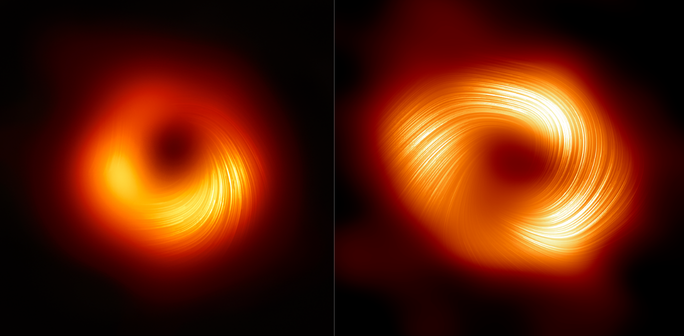
**Figura 1:** Emissão polarizada do buracos negros em M87 e Sgr A*, respectivamente. (ETH Collaboration, 2021,2024)

$\quad$ Um dos principais mecanismos propostos para explicar esse transporte é a instabilidade magnetorrotacional, conhecida como Magnetorotational Instability (MRI). Ela ocorre em fluidos magnetizados com rotação diferencial e mostra que, sob condições apropriadas, mesmo um campo magnético inicialmente fraco pode desestabilizar o escoamento, levando ao desenvolvimento de turbulência magnetohidrodinâmica (MHD). Para compreender melhor esse mecanismo, podemos recorrer a uma analogia com um sistema de duas massas conectadas por uma mola sem massa, que representa a conexão magnética entre diferentes regiões do disco. 


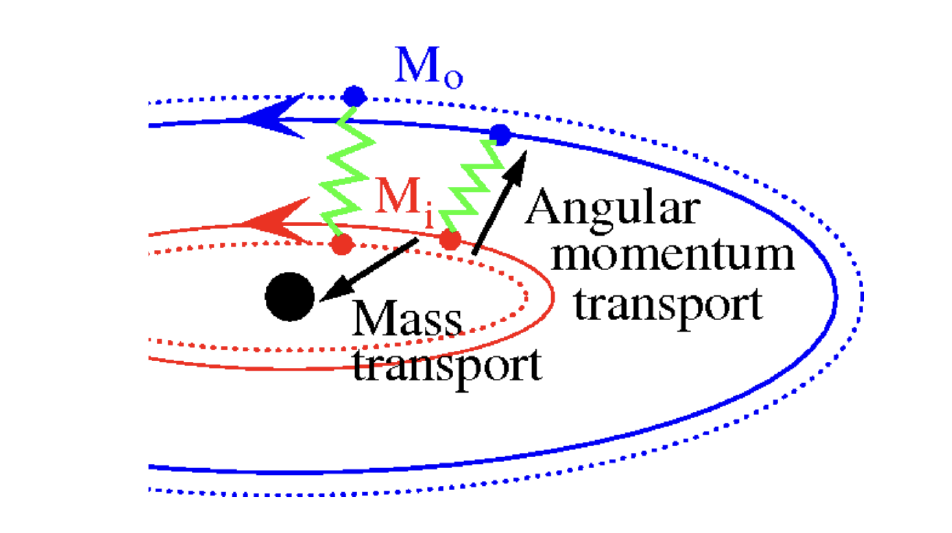
**Figura 2:** Diagrama da analogia da mecânica massa-mola para a instabilidade magnetorotacional. (Mishra,2025)

$\quad$ A mola deve ser entendida como uma conexão relativamente fraca, de modo que pequenas perturbações sejam capazes de deslocar as massas de suas órbitas iniciais. Se a massa vermelha se desloca para uma órbita mais interna, por exemplo, a conexão magnética transmite uma força que transfere momento angular para a massa azul, permitindo que esta se desloque para uma órbita mais externa. Como resultado, ambas se afastam de suas órbitas iniciais, e esse deslocamento pode ser amplificado pela rotação diferencial, fazendo com que as perturbações cresçam progressivamente. Por outro lado, se a conexão magnética fosse excessivamente forte, a tensão magnética tenderia a resistir aos deslocamentos relativos das massas, dificultando o desenvolvimento da instabilidade na escala considerada. Assim, a MRI ilustra como a interação entre um campo magnético fraco e a rotação diferencial pode extrair energia do escoamento e promover o transporte de momento angular necessário à acreção da matéria.

$\quad$ Entretanto, os discos de acreção não são apenas magnetizados: eles também apresentam uma estrutura vertical e uma estratificação térmica que podem favorecer o surgimento de movimentos convectivos. A convecção e a MRI podem, portanto, atuar simultaneamente, influenciando a dinâmica do fluido e o desenvolvimento da turbulência. Nesse contexto, o objetivo do meu projeto é investigar a interação entre esses dois mecanismos, buscando compreender se a convecção térmica pode intensificar ou suprimir a turbulência impulsionada pela MRI.

$\quad$ Para entender como as perturbações magnéticas e térmicas iniciais evoluem antes que o sistema alcance um regime plenamente turbulento, começamos com uma análise de estabilidade linear. Essa abordagem permite estudar o comportamento de pequenas perturbações em torno de um estado de equilíbrio e determinar em quais condições elas permanecem estáveis ou crescem ao longo do tempo, fornecendo uma base para investigar como a interação entre convecção e MRI influencia a dinâmica do disco.

## 2. Aproximação Shearing Box

$\quad$ Modelar um disco de acreção inteiro, levando em conta sua geometria curva e sua dinâmica global, pode ser computacionalmente muito custoso. Para simplificar o problema, podemos estudar uma pequena região do disco e assumir que, nessa escala, as propriedades físicas podem ser descritas localmente. Essa abordagem é conhecida como aproximação shearing box. Nela, selecionamos uma pequena região centrada em um raio \(r_0\) e introduzimos um sistema de coordenadas cartesianas local, com os eixos radial, azimutal e vertical representados por \(x\), \(y\) e \(z\), respectivamente.

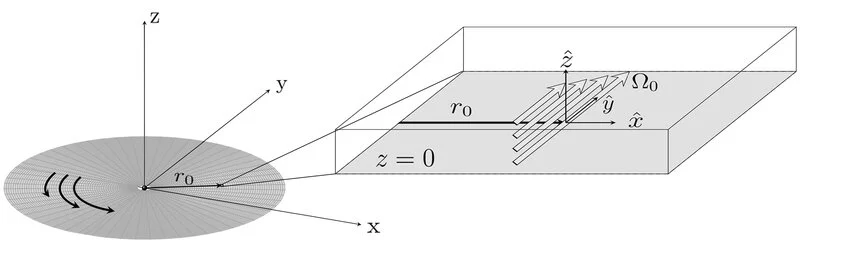
**Figura 3:** Ilustração de uma caixa local para discos de acreção. (Yellin-Bergovoy et al., 2021)

$\quad$ Nesse referencial, a rotação diferencial do disco é descrita localmente por um escoamento de cisalhamento aproximadamente linear, caracterizado pelo parâmetro $q=-d\ln\Omega/d\ln r $, em que $\Omega$ é a velocidade angular do disco. Para um disco Kepleriano, temos $q=3/2$. A condição $q>0$ indica que a velocidade angular diminui com o raio, estabelecendo a rotação diferencial que fornece a energia livre necessária para o desenvolvimento da instabilidade magnetorrotacional (MRI).

$\quad$ Para descrever a dinâmica do fluido e a evolução do campo magnético nessa região, utilizamos as equações da magnetohidrodinâmica (MHD) ideal e incompressível, apresentadas abaixo. Essas equações descrevem a evolução de um fluido condutor, interagindo com um campo magnético no referencial local em rotação, considerando que a viscosidade e a resistividade magnética são desprezíveis.

Equação do momento:

$$
\frac{\partial \mathbf{u}}{\partial t}
+ (\mathbf{u}\cdot\nabla)\mathbf{u}
+ 2\boldsymbol{\Omega}\times\mathbf{u}
=
-\frac{1}{\rho}\nabla P
+\frac{(\mathbf{B}\cdot\nabla)\mathbf{B}}{4\pi\rho}
+2q\Omega^2 x\,\hat{\mathbf{x}}
-\Omega^2 z\,\hat{\mathbf{z}}
\tag{1}
$$

Equação de indução magnética:

$$
\frac{\partial \mathbf{B}}{\partial t}
=
\nabla\times(\mathbf{u}\times\mathbf{B})
\tag{2}
$$

Condições de incompressibilidade e ausência de monopolos magnéticos:

$$
\nabla\cdot\mathbf{u}=0
\tag{3}
$$

$$
\nabla\cdot\mathbf{B}=0
\tag{4}
$$

$\quad$ Nessas equações, $\mathbf{u}$ representa o campo de velocidades do fluido, $\mathbf{B}$ é o campo magnético, $\boldsymbol{\Omega}$ é o vetor de velocidade angular do referencial em rotação, $P$ é a pressão do gás, $\rho$ é a densidade de massa e $t$ representa o tempo.

$\quad$ A primeira equação, denominada equação do momento, descreve o movimento do fluido sob a ação de diferentes forças. No lado esquerdo, o primeiro termo representa a variação temporal da velocidade, enquanto o segundo corresponde à aceleração advectiva do fluido. O terceiro termo representa a força de Coriolis, associada ao referencial em rotação. No lado direito, o gradiente de pressão descreve a força exercida pelas diferenças de pressão, enquanto o termo magnético representa a tensão das linhas de campo magnético. Os dois últimos termos correspondem, respectivamente, à contribuição do cisalhamento radial de fundo e à gravidade vertical efetiva. A tensão magnética corresponde à força transmitida pelas linhas de campo e pode ser associada à analogia da mola que conecta duas massas, apresentada anteriormente na explicação da MRI.

$\quad$ A segunda equação, por sua vez, é a equação de indução magnética, que descreve a evolução temporal do campo magnético em função do movimento do fluido. Na aproximação de MHD ideal, as linhas de campo magnético estão congeladas no escoamento, de modo que podem ser esticadas e deformadas pelo movimento do fluido. Por fim, as duas últimas equações representam as condições de incompressibilidade, $\nabla\cdot\mathbf{u}=0$, que impõe divergência nula ao campo de velocidades, e de ausência de monopolos magnéticos, $\nabla\cdot\mathbf{B}=0$, que estabelece que o campo magnético não possui fontes ou sumidouros isolados.

$\quad$ Essas equações constituem o ponto de partida para a análise de estabilidade linear. A partir delas, podemos introduzir pequenas perturbações nas variáveis do sistema e investigar como elas evoluem, identificando as condições em que o acoplamento entre o campo magnético, a rotação diferencial e a estratificação térmica pode levar ao crescimento de instabilidades.

## 3. Análise de Estabilidade Linear


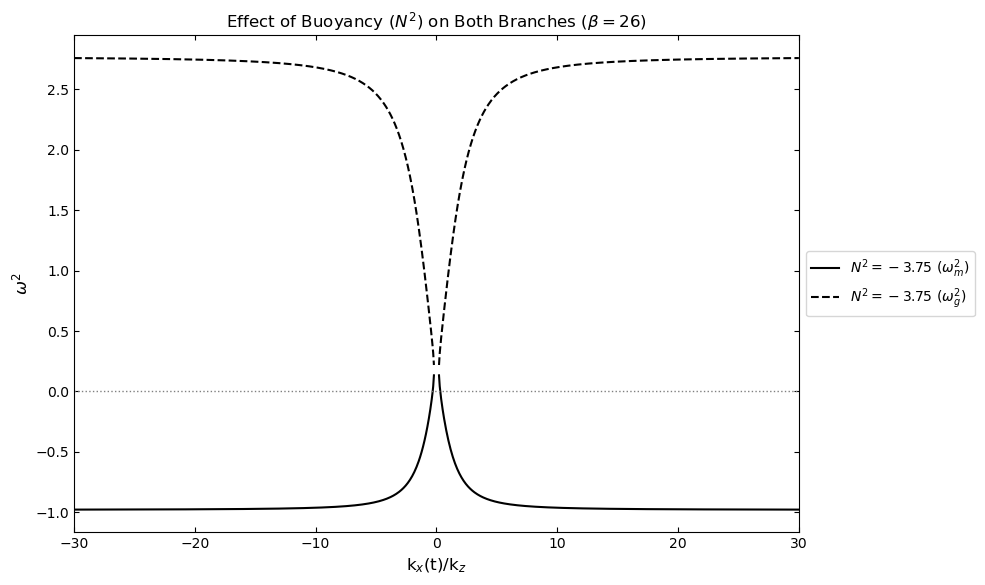

In [2]:
def calculate_w2(N2, beta, q=1.5, kz=6.0, ky_ratio=2.0):
    ky = ky_ratio * kz
    kx_kz = np.linspace(-30, 30, 1000)
    kx = kx_kz * kz
    k2 = kx**2 + ky**2 + kz**2
    
    a1 = (N2 * (ky**2 + kx**2) / k2 
          + 2 * (2 - q) * (kz**2) / k2 
          + 4 * kz**2 / beta 
          - 2 * q * (ky**2) / k2)
    
    a2 = (2 * q * N2 * (ky**2) / k2 
          - 4 * kz**4 / (beta**2) 
          - (2 * kz**2 / beta) * (N2 * (kx**2 + ky**2) / k2 - 2 * q * (ky**2 + kz**2) / k2))
    
    discriminant = a1**2 + 4 * a2
    
    # Replace negative discriminants with NaN so the plot cleanly breaks 
    # when the roots become complex
    valid_discriminant = np.where(discriminant < 0, np.nan, discriminant)
    
    w2_m = (a1 - np.sqrt(valid_discriminant)) / 2
    w2_g = (a1 + np.sqrt(valid_discriminant)) / 2
    
    return kx_kz, w2_m, w2_g

fig, ax = plt.subplots(figsize=(10, 6))

N2_values = [ -3.75]
# N2_values = [0.3,  -.5, -0.8]
#N2_values = [0.25 ,0.0, -0.8]


colors = ['black']
#colors = ['lightgray', 'coral', 'red']
#colors = ['black','lightgray' , 'coral']

beta_value = 26

for N2, color in zip(N2_values, colors):
    kx_kz, w2_m, w2_g = calculate_w2(N2, beta=beta_value)
    
    ax.plot(kx_kz, w2_m, color=color, linewidth=1.5, linestyle='-', 
            label=f'$N^2 = {N2}$ ($\omega_m^2$)')
    
    ax.plot(kx_kz, w2_g, color=color, linewidth=1.5, linestyle='--', 
            label=f'$N^2 = {N2}$ ($\omega_g^2$)')

ax.axhline(0, color='gray', linestyle=':', linewidth=1)
ax.set_xlim(-30, 30)

# ax.set_ylim(-3, 3) 

ax.set_xlabel(r'k$_x$(t)/k$_z$', fontsize=12)
ax.set_ylabel(r'$\omega^2$', fontsize=12)
ax.set_title(rf'Effect of Buoyancy ($N^2$) on Both Branches ($\beta = {beta_value}$)')

ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()

ax.tick_params(axis='both', direction='in', top=True, right=True)

plt.show()

C:\Users\ylana\AppData\Local\Temp\ipykernel_17484\4033975894.py:59: UserWarning: linewidths is ignored by contourf
  contour_m = ax.contourf(N2_grid, beta_grid, w2_m, levels=levels_m, cmap='turbo', linewidths=2, linestyles='solid')


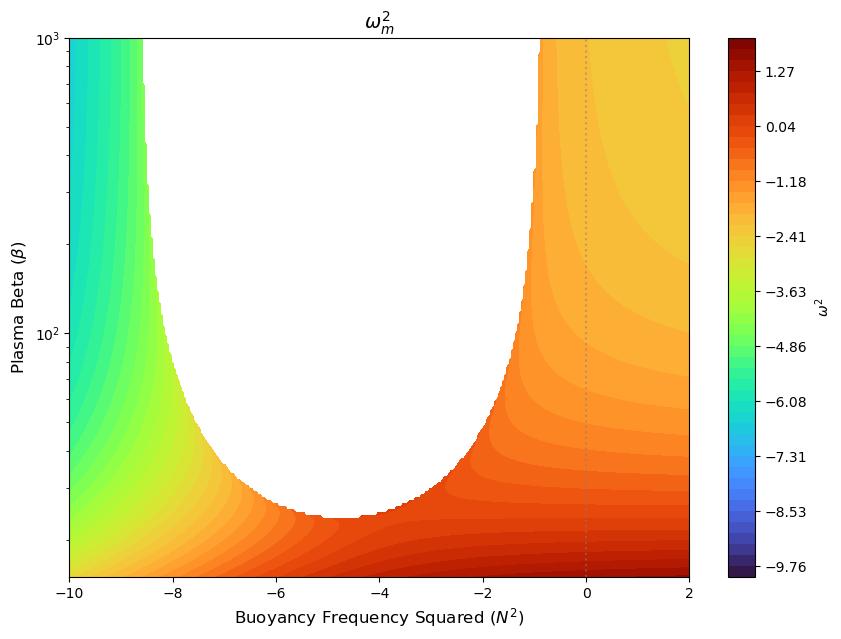

In [1]:

# 1. Fixed Parameters
q = 1.5
kz = 6.0
ky = 2.0 * kz
kx = 0.0  
k2 = kx**2 + ky**2 + kz**2

# 2. Create the Grid
# N2 from convectively unstable (-1.5) to stably stratified (1.5)
N2_vals = np.linspace(-10, 2, 300)
beta_vals = np.logspace(0, np.log10(1000), 300)
# beta_vals = np.linspace(0, 1000, 300)

N2_grid, beta_grid = np.meshgrid(N2_vals, beta_vals)

# 3. Calculate the Coefficients across the grid
a1 = (N2_grid * (ky**2 + kx**2) / k2 
      + 2 * (2 - q) * (kz**2) / k2 
      + 4 * kz**2 / beta_grid 
      - 2 * q * (ky**2) / k2)

a2 = (2 * q * N2_grid * (ky**2) / k2 
      - 4 * kz**4 / (beta_grid**2) 
      - (2 * kz**2 / beta_grid) * (N2_grid * (kx**2 + ky**2) / k2 - 2 * q * (ky**2 + kz**2) / k2))

# 4. Calculate w_m^2 AND w_g^2
discriminant = a1**2 + 4 * a2

# Mask out regions where roots become complex (overstability regime)
valid_discriminant = np.where(discriminant < 0, np.nan, discriminant)

w2_m = (a1 - np.sqrt(valid_discriminant)) / 2
w2_g = (a1 + np.sqrt(valid_discriminant)) / 2  # Adicionada a raiz superior!


# 5. Plotting
fig, ax = plt.subplots(figsize=(10, 7))

# Definimos níveis separados para cada raiz para melhor visualização
# w_m^2 geralmente abriga a instabilidade (valores negativos)
#levels_m = [-10,-5,-3 ,-2.0, -1.0, -0.5, 0.0]
levels_m = np.linspace(-10, 2)
levels_g = np.linspace(-10, 2)

# w_g^2 geralmente representa modos estáveis (valores positivos)
# levels_m = [-10,-5, -3, -2.0, -1.0, -0.5, 0.0]

# Plota w_m^2 (Linhas contínuas, mapa de cor 'viridis_r')
# contour_g = ax.contourf(N2_grid, beta_grid, w2_m - w2_g, levels=levels_m, cmap='viridis') #, linewidths=2, linestyles='solid')

contour_m = ax.contourf(N2_grid, beta_grid, w2_m, levels=levels_m, cmap='turbo', linewidths=2, linestyles='solid')

#contour_g = ax.contourf(N2_grid, beta_grid, w2_g, levels=levels_m, cmap='turbo', linewidths=2, linestyles='dashed')



# ax.clabel(contour_m, inline=True, fontsize=10, fmt=r'$\omega_m^2 = %1.1f$')

# Plota w_g^2 (Linhas tracejadas, mapa de cor 'plasma')
#contour_g = ax.contour(N2_grid, beta_grid, w2_g, levels=levels_g, 
#                       cmap='plasma', linewidths=2, linestyles='dashed')
#ax.clabel(contour_g, inline=True, fontsize=10, fmt=r'$\omega_g^2 = %1.1f$')

#plt.colorbar(contour_m)


cbar2 = plt.colorbar(contour_m)
cbar2.set_label(r'$\omega^2$')




# Formatting axes
ax.set_xlabel(r'Buoyancy Frequency Squared ($N^2$)', fontsize=12)
ax.set_ylabel(r'Plasma Beta ($\beta$)', fontsize=12)
ax.set_title(r'$\omega_m^2$', fontsize=14)

# Add a dashed reference line for neutral stratification (N^2 = 0)
ax.axvline(0, color='gray', linestyle=':', linewidth=1.5, alpha=0.5) 
# Growth rates from each branch


# ---------------------------------------------------------
# NOVO CÓDIGO: Plotar os 16 pontos do cruzamento dos arrays
# ---------------------------------------------------------
beta_pontos = np.array([130, 400, 650, 1000])
N2_pontos = np.array([0.5, -0.25, -0.75, -0.43])

# Criamos um grid com os pontos específicos
N2_pts_grid, beta_pts_grid = np.meshgrid(N2_pontos, beta_pontos)

#Plotamos os pontos (zorder=5 garante que fiquem acima das linhas de contorno)
#ax.scatter(N2_pts_grid, beta_pts_grid, color='red', edgecolor='black', 
#           s=60, zorder=5, label='Points of interest')

# Adicionamos a legenda para identificar os pontos
#ax.legend(loc='best')
# ---------------------------------------------------------

# Fill the complex/overstable region with a light gray so it's clearly distinct
#ax.set_facecolor('#f0f0f0')
#ax.set_yscale('log')
ax.set_ylim(15, 1000)
#ax.set_xlim(-1.5, 1.5)


# ax.tick_params(axis='both', direction='in', top=True, right=True)

plt.yscale('log')

# plt.xscale('log')
plt.show()